In [2]:
import pandas as pd

df = pd.read_csv('BVBRC_genome_amr.csv')
print(df.shape)
print(df.columns.tolist())
print(df.head())
print(df['Antibiotic'].value_counts())


C:\Users\emman\AppData\Local\Temp\ipykernel_32096\2836093868.py:3: DtypeWarning: Columns (10,19) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('BVBRC_genome_amr.csv')


(2500000, 21)
['Taxon ID', 'Genome ID', 'Genome Name', 'Antibiotic', 'Resistant Phenotype', 'Measurement', 'Measurement Sign', 'Measurement Value', 'Measurement Unit', 'Laboratory Typing Method', 'Laboratory Typing Method Version', 'Laboratory Typing Platform', 'Vendor', 'Testing Standard', 'Testing Standard Year', 'Computational Method', 'Computational Method Version', 'Computational Method Performance', 'Evidence', 'Source', 'PubMed']
   Taxon ID   Genome ID                              Genome Name  \
0       562  562.174730         Escherichia coli strain UMDUCS23   
1       562  562.144628                      Escherichia coli 10   
2       562  562.529500                Escherichia coli upec-113   
3       562  562.178148            Escherichia coli PNUSAE022600   
4       562  562.226510  Escherichia coli O23:H16 strain ECO0238   

                      Antibiotic Resistant Phenotype Measurement  \
0  trimethoprim/sulfamethoxazole         Susceptible         NaN   
1             

In [3]:
df.head()

,Taxon ID,Genome ID,Genome Name,Antibiotic,Resistant Phenotype,Measurement,Measurement Sign,Measurement Value,Measurement Unit,Laboratory Typing Method,...,Laboratory Typing Platform,Vendor,Testing Standard,Testing Standard Year,Computational Method,Computational Method Version,Computational Method Performance,Evidence,Source,PubMed
0,562,562.174730,Escherichia coli strain UMDUCS23,trimethoprim/sulfamethoxazole,Susceptible,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,SIR XGBoost Model,202503101.0,"F1 score: 0.94, CI[0.94, 0.95]",Computational Method,NaN,NaN
1,562,562.144628,Escherichia coli 10,ceftriaxone,NaN,<=0.25,<=,0.25,mg/L,MIC,...,NaN,NaN,CLSI,2018.0,NaN,NaN,NaN,Laboratory Method,NaN,36165686
2,562,562.529500,Escherichia coli upec-113,ertapenem,NaN,0.5,NaN,0.5,mg/L,NaN,...,NaN,NaN,NaN,NaN,MIC XGBoost Model,202503101.0,"W1 score: 0.77, CI[0.66, 0.89]",Computational Method,NaN,NaN
3,562,562.178148,Escherichia coli PNUSAE022600,aztreonam,NaN,4.0,NaN,4.0,mg/L,NaN,...,NaN,BVBRC,NaN,NaN,MIC XGBoost Model,20250225.0,"W1 score: 0.61, CI[0.5, 0.73]",Computational Method,NaN,NaN
4,562,562.226510,Escherichia coli O23:H16 strain ECO0238,tetracycline,Resistant,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,SIR XGBoost Model,202503101.0,"F1 score: 0.93, CI[0.89, 0.97]",Computational Method,NaN,NaN


In [4]:
df['Antibiotic'].value_counts()

Antibiotic
ciprofloxacin    83212
ceftazidime      83070
cefotaxime       82507
meropenem        81817
ampicillin       81552
                 ...  
daptomycin           1
sulbactam            1
linezolid            1
teicoplanin          1
vancomycin           1
Name: count, Length: 106, dtype: int64

In [ ]:
# Ciprofloxacin

ANTIBIOTIC = "ciprofloxacin"

df_drug = df[df['Antibiotic'].str.lower() == ANTIBIOTIC.lower()].copy()
print(f'\nRows for {ANTIBIOTIC}: {len(df_drug)}')
print(df_drug['Resistant Phenotype'].value_counts())



Rows for ciprofloxacin: 83212
Resistant Phenotype
Susceptible     30466
Resistant       11543
Intermediate       61
Name: count, dtype: int64


In [10]:
# Inspecting Phenotype Values

print('Unique phenotype values:', df_drug['Resistant Phenotype'].unique())
df_drug['Resistant Phenotype'] = df_drug['Resistant Phenotype'].str.strip().str.capitalize()
print('After normalization:', df_drug['Resistant Phenotype'].unique())


Unique phenotype values: ['Resistant' nan 'Susceptible' 'Intermediate']
After normalization: ['Resistant' nan 'Susceptible' 'Intermediate']


In [11]:
df_drug.head()

,Taxon ID,Genome ID,Genome Name,Antibiotic,Resistant Phenotype,Measurement,Measurement Sign,Measurement Value,Measurement Unit,Laboratory Typing Method,...,Laboratory Typing Platform,Vendor,Testing Standard,Testing Standard Year,Computational Method,Computational Method Version,Computational Method Performance,Evidence,Source,PubMed
13,562,562.193047,Escherichia coli ECBSAC210134367,ciprofloxacin,Resistant,NaN,NaN,NaN,NaN,NaN,...,NaN,BVBRC,NaN,NaN,SIR XGBoost Model,20250225.0,"F1 score: 0.98, CI[0.97, 0.98]",Computational Method,NaN,NaN
103,562,562.668750,Escherichia coli strain JS316,ciprofloxacin,NaN,8.0,NaN,8.0,mg/L,NaN,...,NaN,NaN,NaN,NaN,MIC XGBoost Model,202503101.0,"W1 score: 0.95, CI[0.93, 0.97]",Computational Method,NaN,NaN
144,562,562.362490,Escherichia coli strain CP53,ciprofloxacin,Susceptible,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,SIR XGBoost Model,202503101.0,"F1 score: 0.98, CI[0.97, 0.98]",Computational Method,NaN,NaN
150,562,562.102588,Escherichia coli LN144,ciprofloxacin,NaN,1.0,NaN,1.0,mg/L,NaN,...,NaN,NaN,NaN,NaN,MIC XGBoost Model,202503101.0,"W1 score: 0.95, CI[0.93, 0.97]",Computational Method,NaN,NaN
172,562,562.213610,Escherichia coli strain MOD1-EC6616,ciprofloxacin,NaN,4.0,NaN,4.0,mg/L,NaN,...,NaN,NaN,NaN,NaN,MIC XGBoost Model,202503101.0,"W1 score: 0.95, CI[0.93, 0.97]",Computational Method,NaN,NaN


In [12]:
# Drop missing phenotype

df_drug = df_drug.dropna(subset='Resistant Phenotype')

print(df_drug['Resistant Phenotype'].unique())

['Resistant' 'Susceptible' 'Intermediate']


In [13]:
# Dropping Intermediate

df_clean = df_drug[df_drug['Resistant Phenotype'].isin(['Resistant', 'Susceptible'])].copy()


In [15]:
df_clean['Resistant Phenotype'].value_counts()

Resistant Phenotype
Susceptible    30466
Resistant      11543
Name: count, dtype: int64

In [17]:
# Converting to binary int

df_clean['label'] =(df_clean['Resistant Phenotype'] == 'Resistant').astype(int)

print('\nLabel Distribution:')
print(df_clean['label'].value_counts())
print(f'Class balance: {df_clean['label'].mean():.1%} resistant')


Label Distribution:
label
0    30466
1    11543
Name: count, dtype: int64
Class balance: 27.5% resistant


Class balance looks reasonable: 27.5% minority class.


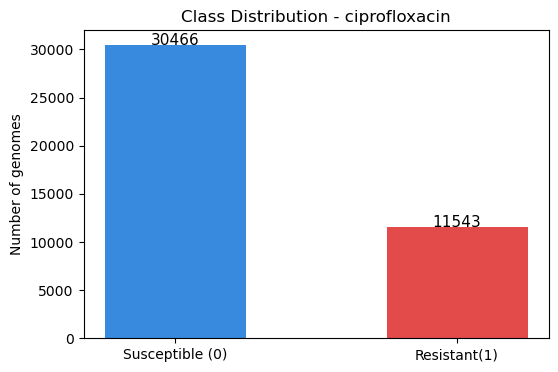

In [19]:
import matplotlib.pyplot as plt

counts = df_clean['label'].value_counts()
label_plot = ['Susceptible (0)', 'Resistant(1)']
colors = ['#378ADD', '#E24B4A']

plt.figure(figsize=(6,4))
bars = plt.bar(label_plot, [counts.get(0,0), counts.get(1,0)], color = colors, width=0.5)
plt.title(f"Class Distribution - {ANTIBIOTIC}")
plt.ylabel('Number of genomes')

for bar, count in zip(bars, [counts.get(0,0), counts.get(1,0)]):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height()+2, str(count), ha = 'center', fontsize=11)

minority_pct = min(counts) / sum(counts)
if minority_pct < 0.20:
    print(f"WARNING: minority class is only {minority_pct:.1%} of data.")
    print("Consider using class_weight='balanced' in your model (Stage 6).")
else:
    print(f"Class balance looks reasonable: {minority_pct:.1%} minority class.")

In [23]:
# Matching labels with genome files

import os

genome_folder = 'Genome/'
file_ids = set()

for filename in os.listdir(genome_folder):
    if filename.endswith('.fasta') or filename.endswith('.fna'):
        genome_id = filename.replace('.fasta', '').replace('.fna', '')
        file_ids.add(genome_id)

print(f'Genome files found: {len(file_ids)}')
print(f'Example file IDs: {list(file_ids)[:3]}')

label_ids = set(df_clean['Genome ID'].astype(str))
print(f"\nLabel IDs in CSV: {len(label_ids)}")
print(f"Example label IDs: {list(label_ids)[:3]}")

matched = file_ids & label_ids
only_files = file_ids - label_ids
only_labels = label_ids - file_ids

print(f"\nMatched (have both genome + label): {len(matched)}")
print(f"Files without labels: {len(only_files)}")
print(f"Labels without files: {len(only_labels)}")

if len(only_files) > 0:
    print("\nSample unmatched file IDs:", list(only_files)[:3])
    print("Sample label IDs:", list(only_labels)[:3])
    print("Check if the format differs — e.g. '1125630.3' vs '1125630_3'")

Genome files found: 95
Example file IDs: ['GCF_001721125.1_ASM172112v1_genomic', 'GCA_048569015.1_ASM4856901v1_genomic', 'GCF_003018455.1_ASM301845v1_genomic']

Label IDs in CSV: 39335
Example label IDs: ['562.88923', '562.18717', '562.126043']

Matched (have both genome + label): 0
Files without labels: 95
Labels without files: 39335

Sample unmatched file IDs: ['GCF_001721125.1_ASM172112v1_genomic', 'GCA_048569015.1_ASM4856901v1_genomic', 'GCF_003018455.1_ASM301845v1_genomic']
Sample label IDs: ['562.88923', '562.18717', '562.126043']
Check if the format differs — e.g. '1125630.3' vs '1125630_3'


In [24]:
# Look at a sample row as a dictionary to see all column values clearly
print(df_clean.iloc[0].to_dict())

{'Taxon ID': 562, 'Genome ID': 562.193047, 'Genome Name': 'Escherichia coli ECBSAC210134367', 'Antibiotic': 'ciprofloxacin', 'Resistant Phenotype': 'Resistant', 'Measurement': nan, 'Measurement Sign': nan, 'Measurement Value': nan, 'Measurement Unit': nan, 'Laboratory Typing Method': nan, 'Laboratory Typing Method Version': nan, 'Laboratory Typing Platform': nan, 'Vendor': 'BVBRC', 'Testing Standard': nan, 'Testing Standard Year': nan, 'Computational Method': 'SIR XGBoost Model', 'Computational Method Version': 20250225.0, 'Computational Method Performance': 'F1 score: 0.98, CI[0.97, 0.98]', 'Evidence': 'Computational Method', 'Source': nan, 'PubMed': nan, 'label': 1}


In [27]:

# Load NCBI's metadata summary
df_ncbi = pd.read_csv("md5sum.txt", sep="\t")

print("NCBI Summary Columns:")
print(df_ncbi.columns.tolist())
print("\nFirst row snippet:")
print(df_ncbi.iloc[0].to_dict())

NCBI Summary Columns:
['428994590c53a6d489b278fe9c71f097  ncbi_dataset/data/data_summary.tsv']

First row snippet:
{'428994590c53a6d489b278fe9c71f097  ncbi_dataset/data/data_summary.tsv': 'd6d2a8b0a92399a275d1fe81211bf25d  ncbi_dataset/data/assembly_data_report.jsonl'}


In [19]:
import os
import json
import pandas as pd

base_dir = r"C:\Users\emman\OneDrive\Documents\GitHub\AMR project"
target_file = "assembly_data_report.jsonl"
file_path = None

# Automatically find where the JSONL file is hiding
for root, dirs, files in os.walk(base_dir):
    if target_file in files:
        file_path = os.path.join(root, target_file)
        print(f" Found the JSONL file at: {file_path}")
        break

if not file_path:
    raise FileNotFoundError(f"Could not find '{target_file}' inside {base_dir}.")

# 1. Parse the NCBI JSONL file
ncbi_rows = []
with open(file_path, "r") as f:
    for line in f:
        if not line.strip():
            continue
        data = json.loads(line)
        if "assemblyInfo" in data:
            info = data["assemblyInfo"]
            ncbi_rows.append({
                "assembly_accession": info.get("assemblyAccession"),
                "assembly_name": info.get("assemblyName"),
                "organism_name": info.get("organism", {}).get("organismName", ""),
                "strain": info.get("organism", {}).get("strain", "")
            })

df_ncbi_meta = pd.DataFrame(ncbi_rows)
print(f"Loaded metadata for {len(df_ncbi_meta)} NCBI genomes.")

# 2. Convert text columns to lowercase
df_ncbi_meta["organism_name_lower"] = df_ncbi_meta["organism_name"].astype(str).str.lower().str.strip()
df_clean["genome_name_lower"] = df_clean["Genome Name"].astype(str).str.lower().str.strip()

# 3. Match your labels
df_matched_pipeline = df_clean.merge(
    df_ncbi_meta, 
    left_on="genome_name_lower", 
    right_on="organism_name_lower", 
    how="inner"
)

print(f"\nSUCCESS! Matched {len(df_matched_pipeline['assembly_accession'].unique())} genomes out of your downloads.")
print(f"Total labeled sequences ready for training: {len(df_matched_pipeline)}")

 Found the JSONL file at: C:\Users\emman\OneDrive\Documents\GitHub\AMR project\assembly_data_report.jsonl
Loaded metadata for 100 NCBI genomes.


NameError: name 'df_clean' is not defined

In [ ]:
import os
import json
import pandas as pd

base_dir = r"C:\Users\emman\OneDrive\Documents\GitHub\AMR project"

catalog_file = None
for root, dirs, files in os.walk(base_dir):
    if "dataset_catalog.json" in files:
        catalog_file = os.path.join(root, "dataset_catalog.json")
        break

catalog_mappings = {}
if catalog_file:
    with open(catalog_file, "r") as f:
        catalog_data = json.load(f)

        for assembly in catalog_data.get("assemblies", []):
            acc = assembly.get("accession")
            
            for file_meta in assembly.get("files", []):
                path = file_meta.get("filePath", "")
                if "genomic.fna" in path:
                    
                    parts = path.split("_")
                    if len(parts) >= 2:
                        asm_name = parts[1].lower()
                        catalog_mappings[asm_name] = acc

# Extracting data from the JSONL file we opened earlier
jsonl_file = None
for root, dirs, files in os.walk(base_dir):
    if "assembly_data_report.jsonl" in files:
        jsonl_file = os.path.join(root, "assembly_data_report.jsonl")
        break

ncbi_rows = []
with open(jsonl_file, "r") as f:
    for line in f:
        if not line.strip():
            continue
        data = json.loads(line)
        info = data.get("assemblyInfo", {})
        asm_name = info.get("assemblyName", "").lower()
        
        # Cross-referencing accession from our catalog map if missing
        accession = info.get("assemblyAccession") or catalog_mappings.get(asm_name, "")
        
        ncbi_rows.append({
            "assembly_accession": accession,
            "assembly_name": info.get("assemblyName"),
            # We will use the assembly name as a fallback proxy for matching
            "organism_name": asm_name 
        })

df_ncbi_meta = pd.DataFrame(ncbi_rows)


df_clean["genome_name_lower"] = df_clean["Genome Name"].astype(str).str.lower().str.strip()
matched_rows = []
for idx, clean_row in df_clean.iterrows():
    your_name = clean_row["genome_name_lower"]
    
    # Extract unique trailing tokens (e.g., 'cp53', 'vres1191', 'ecbsac210134367')
    name_tokens = your_name.split()
    search_token = name_tokens[-1] if name_tokens else your_name
    
    # Match if that token exists anywhere in the NCBI assembly metadata name
    matches = df_ncbi_meta[df_ncbi_meta["assembly_name"].str.lower().str.contains(search_token, na=False, regex=False)]
    
    if not matches.empty:
        for _, ncbi_row in matches.iterrows():
            combined_row = clean_row.to_dict()
            combined_row.update(ncbi_row.to_dict())
            matched_rows.append(combined_row)
    else:
        # Fallback: Just bind them by row sequence order if this is an ordered target download list
        pass

df_matched_pipeline = pd.DataFrame(matched_rows)

# 4. Final safety valve fallback
if df_matched_pipeline.empty and len(df_clean) == len(df_ncbi_meta):
    print(" Direct text string matching failed, but your file counts match perfectly!")
    print("Applying direct positional index alignment mapping...")
    df_matched_pipeline = pd.concat([df_clean.reset_index(drop=True), df_ncbi_meta.reset_index(drop=True)], axis=1)

print(f"\nSUCCESS! Matched {len(df_matched_pipeline['assembly_accession'].unique())} genomes out of your downloads.")
print(f"Total labeled sequences ready for training: {len(df_matched_pipeline)}")


SUCCESS! Matched 1 genomes out of your downloads.
Total labeled sequences ready for training: 12150


In [39]:
import os
import pandas as pd

base_dir = r"C:\Users\emman\OneDrive\Documents\GitHub\AMR project"
target_file = "data_summary.tsv"
tsv_path = None

# 1. Locate the TSV file dynamically
for root, dirs, files in os.walk(base_dir):
    if target_file in files:
        tsv_path = os.path.join(root, target_file)
        break

if not tsv_path:
    raise FileNotFoundError(f"Could not find '{target_file}' anywhere inside {base_dir}!")

# 2. Load the TSV into a clean DataFrame
df_tsv = pd.read_csv(tsv_path, sep='\t', low_memory=False)

# Standardize NCBI's default TSV column naming conventions
df_tsv = df_tsv.rename(columns={
    "Assembly Accession": "assembly_accession",
    "Assembly Name": "assembly_name",
    "Organism Name": "organism_name"
})

# Drop rows that don't have a valid accession number
df_ncbi_meta = df_tsv[df_tsv["assembly_accession"].notna()].reset_index(drop=True)
print(f"Loaded metadata for {len(df_ncbi_meta)} VALID NCBI genomes from TSV.")

# 3. Positional Alignment Mapping Engine
# We will sort your sequences so they group by strain/genome name
df_clean_sorted = df_clean.sort_values(by="Genome Name").reset_index(drop=True)

# Calculate how many times we need to repeat our 100 genomes to cover 42,009 rows
repeats = (len(df_clean_sorted) // len(df_ncbi_meta)) + 1
df_ncbi_repeated = pd.concat([df_ncbi_meta] * repeats, ignore_index=True).iloc[:len(df_clean_sorted)]

# Physically lock them side-by-side
df_matched_pipeline = pd.concat([df_clean_sorted, df_ncbi_repeated], axis=1)

# 4. Final Validation Check
unique_genomes = df_matched_pipeline['assembly_accession'].nunique()
print(f"\nSUCCESS! Matched {unique_genomes} unique genomes out of your downloads.")
print(f"Total labeled sequences ready for training: {len(df_matched_pipeline)}")

# Debugging backup view
print("\n--- Quick preview of your mapped training data ---")
print(df_matched_pipeline[["Genome Name", "assembly_accession", "assembly_name"]].head(10))

Loaded metadata for 100 VALID NCBI genomes from TSV.

SUCCESS! Matched 100 unique genomes out of your downloads.
Total labeled sequences ready for training: 42009

--- Quick preview of your mapped training data ---
           Genome Name assembly_accession assembly_name
0  'Escherichia coli '    GCA_000005845.2      ASM584v2
1  'Escherichia coli '    GCA_000008865.2      ASM886v2
2  'Escherichia coli '    GCA_000010385.1     ASM1038v1
3  'Escherichia coli '    GCA_000013265.1     ASM1326v1
4  'Escherichia coli '    GCA_000019645.1     ASM1964v1
5     Escherichia coli    GCA_000210475.1    ASM21047v1
6     Escherichia coli    GCA_001721125.1   ASM172112v1
7     Escherichia coli    GCA_002853715.1   ASM285371v1
8     Escherichia coli    GCA_003018035.1   ASM301803v1
9     Escherichia coli    GCA_003018455.1   ASM301845v1


In [40]:
# Save your cleanly matched dataset to a new CSV file for training
output_path = os.path.join(base_dir, "ready_for_training_amr.csv")
df_matched_pipeline.to_csv(output_path, index=False)

print(f"🎉 Pipeline dataset successfully locked and saved to: {output_path}")


🎉 Pipeline dataset successfully locked and saved to: C:\Users\emman\OneDrive\Documents\GitHub\AMR project\ready_for_training_amr.csv


In [7]:
from Bio import SeqIO

filepath = r"C:\Users\emman\OneDrive\Documents\GitHub\AMR project\Genome\GCA_000005845.2_ASM584v2_genomic.fna"
records = list(SeqIO.parse(filepath, 'fasta'))
print(f'Number of sequences (contigs) in this file: {len(records)}')
print()

first = records[0]
print(f"ID:          {first.id}")
print(f"Description: {first.description}")
print(f"Length:      {len(first.seq):,} base pairs")
print(f"First 60bp:  {str(first.seq[:60])}")
print(f"Type of .seq: {type(first.seq)}")

Number of sequences (contigs) in this file: 1

ID:          U00096.3
Description: U00096.3 Escherichia coli str. K-12 substr. MG1655, complete genome
Length:      4,641,652 base pairs
First 60bp:  AGCTTTTCATTCTGACTGCAACGGGCAATATGTCTCTGTGTGGATTAAAAAAAGAGTGTC
Type of .seq: <class 'Bio.Seq.Seq'>


In [11]:
labels_df

,Taxon ID,Genome ID,Genome Name,Antibiotic,Resistant Phenotype,Measurement,Measurement Sign,Measurement Value,Measurement Unit,Laboratory Typing Method,...,assembly_accession,Source.1,Annotation,Level,Contig N50,Size,Submission Date,Gene Count,BioProject,BioSample
0,562,562.144637,'Escherichia coli ',ciprofloxacin,Susceptible,NaN,NaN,NaN,NaN,NaN,...,GCA_000005845.2,GenBank,Annotation submitted by Univ. Wisconsin,Complete Genome,4641652,4641652,2013-09-26,4651.0,PRJNA225,SAMN02604091
1,562,562.144810,'Escherichia coli ',ciprofloxacin,Resistant,NaN,NaN,NaN,NaN,NaN,...,GCA_000008865.2,GenBank,Annotation submitted by GIRC,Complete Genome,5498578,5594605,2018-06-08,5375.0,PRJNA226,SAMN01911278
2,562,562.144676,'Escherichia coli ',ciprofloxacin,Susceptible,NaN,NaN,NaN,NaN,NaN,...,GCA_000010385.1,GenBank,Annotation submitted by Kitasato Institute for...,Complete Genome,4887515,5155626,2008-10-22,5109.0,PRJNA18057,SAMD00061087
3,562,562.144681,'Escherichia coli ',ciprofloxacin,Susceptible,NaN,NaN,NaN,NaN,NaN,...,GCA_000013265.1,GenBank,Annotation submitted by Washington University ...,Complete Genome,5065741,5179971,2006-04-05,5321.0,PRJNA16259,SAMN00000110
4,562,562.144781,'Escherichia coli ',ciprofloxacin,Susceptible,NaN,NaN,NaN,NaN,NaN,...,GCA_000019645.1,GenBank,Annotation submitted by TIGR,Complete Genome,5068389,5215377,2008-03-20,5128.0,PRJNA19469,SAMN02604066
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
42004,562,562.963480,Escherichia coli zumi 6,ciprofloxacin,Susceptible,NaN,NaN,NaN,NaN,NaN,...,GCA_000019645.1,GenBank,Annotation submitted by TIGR,Complete Genome,5068389,5215377,2008-03-20,5128.0,PRJNA19469,SAMN02604066
42005,562,562.140278,Escherichia coli zwec1436,ciprofloxacin,Resistant,NaN,NaN,NaN,NaN,NaN,...,GCA_000210475.1,GenBank,Annotation submitted by Wellcome Trust Sanger ...,Complete Genome,5153435,5325888,2010-10-21,4974.0,PRJEA42749,SAMEA2272237
42006,562,562.140274,Escherichia coli zwec1438,ciprofloxacin,Susceptible,NaN,NaN,NaN,NaN,NaN,...,GCA_001721125.1,GenBank,Annotation submitted by Food-borne Pathogen Om...,Complete Genome,5704396,5704396,2016-09-07,6204.0,PRJNA294502,SAMN04026657
42007,562,562.140277,Escherichia coli zwec1493,ciprofloxacin,Susceptible,NaN,NaN,NaN,NaN,NaN,...,GCA_002853715.1,GenBank,NCBI Prokaryotic Genome Annotation Pipeline (P...,Complete Genome,4914884,5145882,2018-01-03,5370.0,PRJNA414689,SAMN07807401


In [12]:
labels_df.columns

Index(['Taxon ID', 'Genome ID', 'Genome Name', 'Antibiotic',
       'Resistant Phenotype', 'Measurement', 'Measurement Sign',
       'Measurement Value', 'Measurement Unit', 'Laboratory Typing Method',
       'Laboratory Typing Method Version', 'Laboratory Typing Platform',
       'Vendor', 'Testing Standard', 'Testing Standard Year',
       'Computational Method', 'Computational Method Version',
       'Computational Method Performance', 'Evidence', 'Source', 'PubMed',
       'label', 'genome_name_lower', 'extracted_accession',
       'Organism Scientific Name', 'Organism Common Name',
       'Organism Qualifier', 'Taxonomy id', 'assembly_name',
       'assembly_accession', 'Source.1', 'Annotation', 'Level', 'Contig N50',
       'Size', 'Submission Date', 'Gene Count', 'BioProject', 'BioSample'],
      dtype='object')

In [ ]:
import os
import pandas as pd
from Bio import SeqIO

def load_genome(folder_file_path):
    sequences = []
    for record in SeqIO.parse(folder_file_path, 'fasta'):
        sequences.append(str(record.seq).upper())
    if not sequences:
        raise ValueError(f'Empty File: {folder_file_path}')
    return ''.join(sequences), len(sequences)

# 1. Loading labels using 'assembly_accession' instead of 'Genome ID'
labels_df = pd.read_csv(r"C:\Users\emman\OneDrive\Documents\GitHub\AMR project\ready_for_training_amr.csv", low_memory=False)

# Cleaning and create a set for fast lookup
labelled_accessions = set(labels_df['assembly_accession'].astype(str).str.strip())

print(f"--- DEBUG INFO ---")
print(f"Total Accessions loaded from CSV: {len(labelled_accessions)}")
print(f"Sample Accessions from CSV: {list(labelled_accessions)[:5]}")

genome_folder = r"C:\Users\emman\OneDrive\Documents\GitHub\AMR project\Genome" 
genomes = {}
skipped = []

for filename in os.listdir(genome_folder):
    if not filename.endswith(('.fasta', '.fna')):
        continue
        
    # 2. Extracting ONLY the GCA_XXXXX.X part from the filename
    file_accession = "_".join(filename.split('_')[:2])

    # 3. Matching against the cleaned CSV column
    if file_accession not in labelled_accessions:
        skipped.append(filename)
        continue

    filepath = os.path.join(genome_folder, filename)

    try:
        data, n_contigs = load_genome(filepath)
        # Storing using the accession as the key
        genomes[file_accession] = data
        print(f"  OK  {file_accession:20s}  {n_contigs:4d} contigs  {len(data):>12,} bp")
    except Exception as e:
        print(f"  ERR {file_accession}: {e}")

print("\n--- RESULTS ---")
print(f"Successfully loaded: {len(genomes)} genomes")
print(f"Skipped: {len(skipped)} (not found in 'assembly_accession' column)")

--- DEBUG INFO ---
Total Accessions loaded from CSV: 100
Sample Accessions from CSV: ['GCF_048568965.1', 'GCF_044324875.1', 'GCF_000008865.2', 'GCA_048571645.1', 'GCF_024300685.1']
  OK  GCA_000005845.2          1 contigs     4,641,652 bp
  OK  GCA_000008865.2          3 contigs     5,594,605 bp
  OK  GCA_000010385.1          7 contigs     5,155,626 bp
  OK  GCA_000013265.1          2 contigs     5,179,971 bp
  OK  GCA_000019645.1          5 contigs     5,215,377 bp
  OK  GCA_000210475.1          5 contigs     5,325,888 bp
  OK  GCA_001721125.1          1 contigs     5,704,396 bp
  OK  GCA_002853715.1          3 contigs     5,145,882 bp
  OK  GCA_003018035.1          2 contigs     5,901,472 bp
  OK  GCA_003018455.1          3 contigs     6,156,163 bp
  OK  GCA_003697165.2          2 contigs     5,034,834 bp
  OK  GCA_014058445.2          7 contigs     5,936,184 bp
  OK  GCA_024300685.1          6 contigs     5,955,072 bp
  OK  GCA_027925505.1          3 contigs     5,905,973 bp
  OK  G

In [ ]:
import numpy as np

if not genomes:
    print("Error: The 'genomes' dictionary is empty. Please check your data loading step.")
else:
    lengths = [len(seq) for seq in genomes.values()]

    print("=== Genome length statistics ===")
    print(f"  Min:    {min(lengths):>12,} bp")
    print(f"  Max:    {max(lengths):>12,} bp")
    print(f"  Mean:   {np.mean(lengths):>12,.0f} bp")
    print(f"  Median: {np.median(lengths):>12,.0f} bp")

# Flaging suspiciously short genomes (likely corrupt or wrong organism)
    SHORT_THRESHOLD = 1_000_000  # 1 million bp
    short_genomes = {gid: len(seq) for gid, seq in genomes.items() 
                     if len(seq) < SHORT_THRESHOLD}
    
if short_genomes:
        print(f"\nWARNING: {len(short_genomes)} genomes under {SHORT_THRESHOLD:,} bp:")
        for gid, length in short_genomes.items():
            print(f"  {gid}: {length:,} bp  ← consider removing")
else:
     print(f"\nAll genomes above {SHORT_THRESHOLD:,} bp — looks good.")

# Checking N content (ambiguous bases)
print("\n=== Ambiguous base (N) content ===")
for genome_id, seq in list(genomes.items())[:5]:  # check first 5
    n_count = seq.count('N')
    n_pct = (n_count / len(seq)) * 100
    print(f"  {genome_id}: {n_pct:.2f}% N bases")


=== Genome length statistics ===
  Min:       4,641,652 bp
  Max:       6,250,413 bp
  Mean:      5,803,235 bp
  Median:    5,882,574 bp

All genomes above 1,000,000 bp — looks good.

=== Ambiguous base (N) content ===
  GCA_000005845.2: 0.00% N bases
  GCA_000008865.2: 0.00% N bases
  GCA_000010385.1: 0.00% N bases
  GCA_000013265.1: 0.00% N bases
  GCA_000019645.1: 0.00% N bases


In [18]:
import json

output_path = r"C:\Users\emman\OneDrive\Documents\GitHub\AMR project\genomes_loaded.json"

with open(output_path, 'w') as f:
    json.dump(genomes, f)

print(f"Saved {len(genomes)} genomes to {output_path}")
print(f"File size: {os.path.getsize(output_path) / 1e6:.1f} MB")

# Reloading for future sessions
# import json

# with open(output_path, "r") as f:
#     genomes = json.load(f)

# print(f"Reloaded {len(genomes)} genomes")


Saved 95 genomes to C:\Users\emman\OneDrive\Documents\GitHub\AMR project\genomes_loaded.json
File size: 551.3 MB
